# 06 — Figura de síntese da análise espacial

Este notebook monta uma figura diretamente das tabelas já produzidas: (a) distância média relativa nas combinações de renda e densidade; (b) parcela acima do P90 em cada combinação; (c) setores associados a cada atendimento em Fortaleza; (d) setores de Fortaleza com distância igual ou maior ao P90. SUS é o recorte principal.

As médias e proporções são copiadas das tabelas calculadas no notebook 04 de mapas. Este notebook não recalcula o indicador de distância. A atribuição considera a menor soma das ligações à rua e do percurso pela rede. A figura é vetorial, com os mapas desenhados a partir dos polígonos dos setores. A área de Ilha de Maré não entra nos resumos de distância porque os setores correspondentes ultrapassam o corte de 2 km da ligação à rua.

In [1]:
from pathlib import Path
import sys
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown
RAIZ=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"PLANO.md").exists())
DIR=RAIZ/"dados/processados/retomada/mapas_grupos_P90"
FIG=RAIZ/"figuras/final"; FIG.mkdir(parents=True,exist_ok=True)


## 1. Carregar os números e geometrias já calculados

In [2]:
grupos=pd.read_csv(DIR/"grupos_16_renda_densidade.csv")
setores=pd.read_csv(DIR/"setores_com_P90_e_quartis.csv",dtype={"CD_SETOR":str,"CO_CNES":str})
fort=setores.query("capital == 'Fortaleza - CE' and versao == 'SUS'").copy()
assert fort.CD_SETOR.is_unique
malha=gpd.read_file(RAIZ/"dados/ibge/setores_gpkg/CE_setores_CD2022.gpkg",where="CD_MUN='2304400'",columns=["CD_SETOR","CD_SIT"]).to_crs(32724)
malha=malha.loc[malha.CD_SIT!="9"].copy()
mapa=malha.merge(fort[["CD_SETOR","CO_CNES","muito_longe"]],on="CD_SETOR",how="left",validate="many_to_one")
assert len(mapa)==len(malha)
print("Fortaleza: ",len(fort),"setores com distância SUS válida; ",mapa.CO_CNES.notna().sum(),"geometrias associadas.")


Fortaleza:  4306 setores com distância SUS válida;  4306 geometrias associadas.


## 2. Desenhar os quatro painéis aprovados

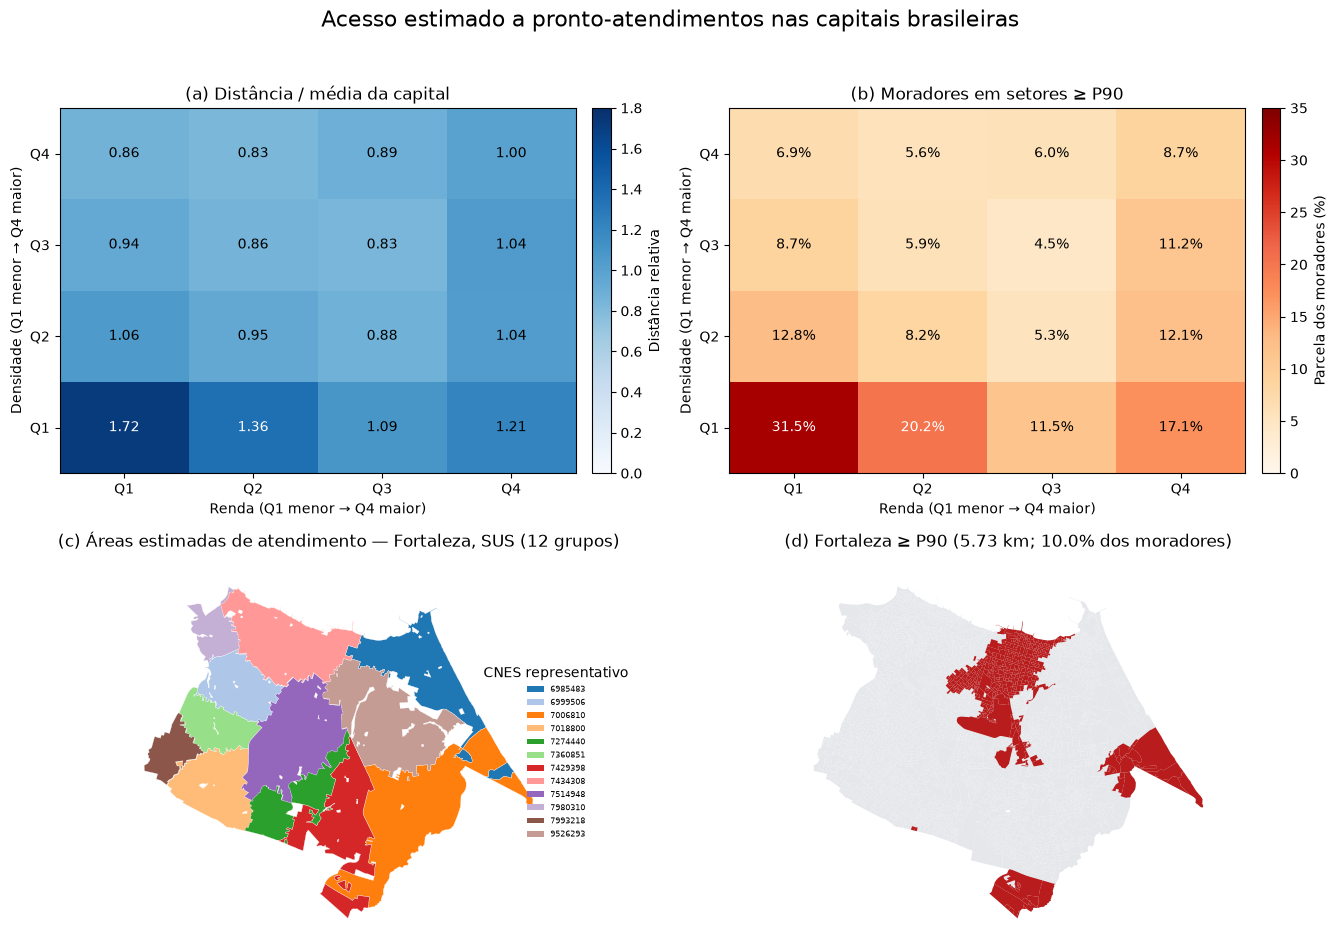

Os painéis (a) e (b) reúnem resultados das 26 capitais. Os mapas (c) e (d) detalham Fortaleza. São descrições do recorte analisado; não demonstram causalidade nem capacidade de atendimento.

In [3]:
fig,axs=plt.subplots(2,2,figsize=(13.5,9.5))
# (a) Distância relativa, valores agregados entre capitais por grupo.
g=grupos.query("versao=='SUS'")
mat=g.pivot(index="q_densidade",columns="q_renda",values="distancia_relativa_media").reindex(index=[4,3,2,1],columns=[1,2,3,4])
im=axs[0,0].imshow(mat,cmap="Blues",vmin=0,vmax=1.8,aspect="auto")
for i in range(4):
    for j in range(4): axs[0,0].text(j,i,f"{mat.iloc[i,j]:.2f}",ha="center",va="center",color="white" if mat.iloc[i,j]>1.3 else "black",fontsize=10)
axs[0,0].set(xticks=range(4),xticklabels=["Q1","Q2","Q3","Q4"],yticks=range(4),yticklabels=["Q4","Q3","Q2","Q1"],xlabel="Renda (Q1 menor → Q4 maior)",ylabel="Densidade (Q1 menor → Q4 maior)",title="(a) Distância / média da capital")
fig.colorbar(im,ax=axs[0,0],fraction=.046,pad=.03,label="Distância relativa")
# (b) População em setores acima do P90 da capital.
mat2=g.pivot(index="q_densidade",columns="q_renda",values="parcela_muito_longe_pct").reindex(index=[4,3,2,1],columns=[1,2,3,4])
im2=axs[0,1].imshow(mat2,cmap="OrRd",vmin=0,vmax=35,aspect="auto")
for i in range(4):
    for j in range(4): axs[0,1].text(j,i,f"{mat2.iloc[i,j]:.1f}%",ha="center",va="center",color="black" if mat2.iloc[i,j]<20 else "white",fontsize=10)
axs[0,1].set(xticks=range(4),xticklabels=["Q1","Q2","Q3","Q4"],yticks=range(4),yticklabels=["Q4","Q3","Q2","Q1"],xlabel="Renda (Q1 menor → Q4 maior)",ylabel="Densidade (Q1 menor → Q4 maior)",title="(b) Moradores em setores ≥ P90")
fig.colorbar(im2,ax=axs[0,1],fraction=.046,pad=.03,label="Parcela dos moradores (%)")
# (c) Uma cor por área estimada de atendimento.
areas=mapa.loc[mapa.CO_CNES.notna()].dissolve(by="CO_CNES",as_index=False)
ids=sorted(areas.CO_CNES.astype(str)); paleta=plt.get_cmap("tab20",max(20,len(ids)))
cores={id_:paleta(i) for i,id_ in enumerate(ids)}
for _,r in areas.iterrows(): gpd.GeoSeries([r.geometry],crs=areas.crs).plot(ax=axs[1,0],color=cores[str(r.CO_CNES)],linewidth=.2,edgecolor="white")
axs[1,0].set_title(f"(c) Áreas estimadas de atendimento — Fortaleza, SUS ({len(ids)} grupos)"); axs[1,0].set_axis_off()
handles=[Patch(facecolor=cores[i],label=i) for i in ids]
axs[1,0].legend(handles=handles,title="CNES representativo",loc="center left",bbox_to_anchor=(.82,.5),fontsize=6,ncol=1,frameon=False)
# (d) Setores com distância igual ou maior ao P90 local.
mapa.plot(ax=axs[1,1],color="#e5e7eb",linewidth=0)
mapa.loc[mapa.muito_longe.fillna(False)].plot(ax=axs[1,1],color="#b91c1c",linewidth=0)
p90=float(fort.P90_m.iloc[0]); parcela=100*fort.loc[fort.muito_longe,"populacao"].sum()/fort.populacao.sum()
axs[1,1].set_title(f"(d) Fortaleza ≥ P90 ({p90/1000:.2f} km; {parcela:.1f}% dos moradores)"); axs[1,1].set_axis_off()
fig.suptitle("Acesso estimado a pronto-atendimentos nas capitais brasileiras",fontsize=16,y=.99)
fig.tight_layout(rect=(0,0,1,.965))
fig.savefig(FIG/"figura_principal.png",dpi=240,bbox_inches="tight")
fig.savefig(FIG/"figura_principal.pdf",bbox_inches="tight")
plt.show()
display(Markdown("Os painéis (a) e (b) reúnem resultados das 26 capitais. Os mapas (c) e (d) detalham Fortaleza. São descrições do recorte analisado; não demonstram causalidade nem capacidade de atendimento."))
